# Quantum Channels

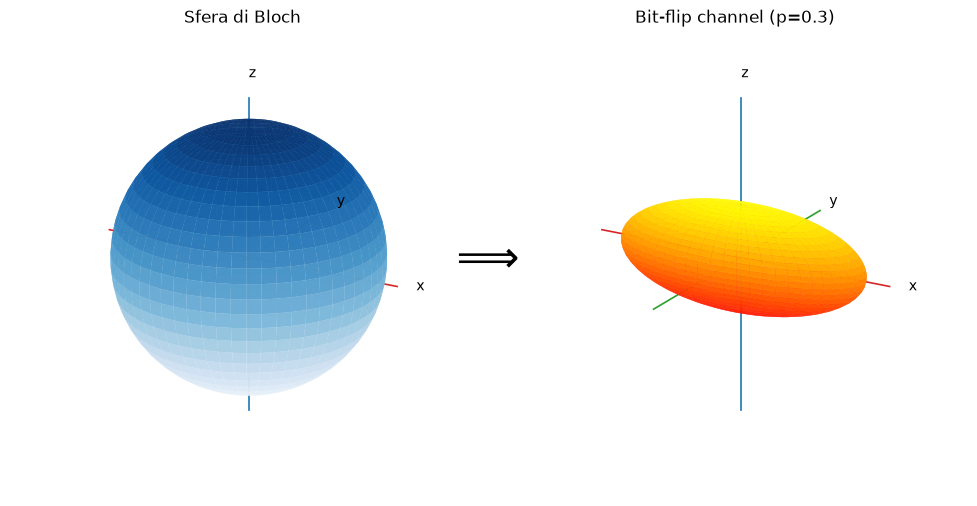

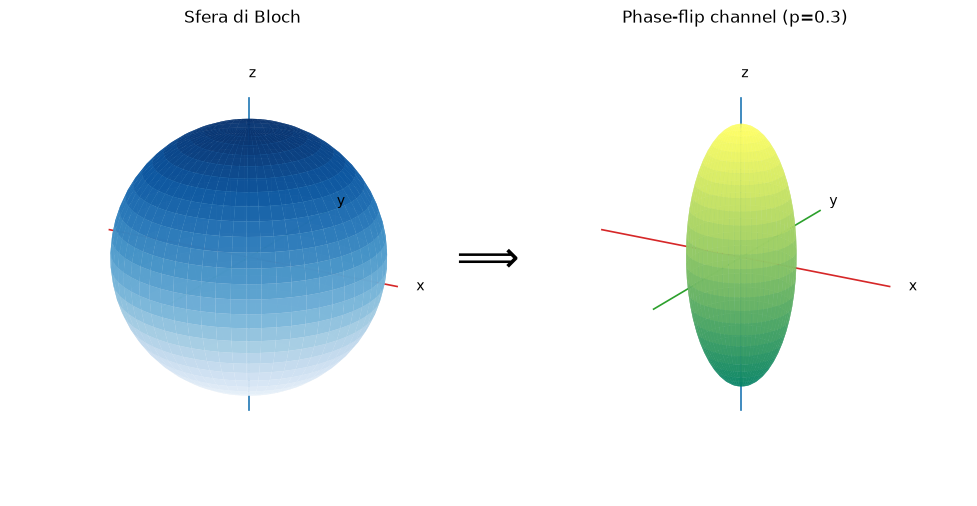

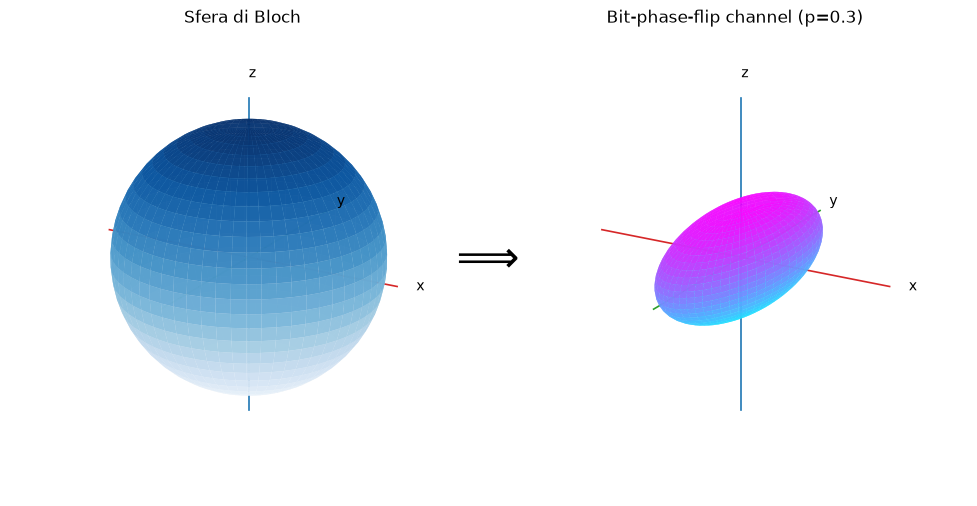

In [10]:
%matplotlib inline

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

p = 0.3
f = 1 - 2*p  # fattore di contrazione

def sfera(sx=1, sy=1, sz=1, n_u=60, n_v=30):
    u = np.linspace(0, 2*np.pi, n_u)
    v = np.linspace(0, np.pi, n_v)
    x = sx*np.outer(np.cos(u), np.sin(v))
    y = sy*np.outer(np.sin(u), np.sin(v))
    z = sz*np.outer(np.ones_like(u), np.cos(v))
    return x, y, z

def pannello(ax, sx, sy, sz, cmap, titolo):
    x, y, z = sfera(sx, sy, sz)
    # colore in base alla quota z
    norm = Normalize(z.min(), z.max())
    ax.plot_surface(x, y, z, facecolors=matplotlib.colormaps[cmap](norm(z)),
                rstride=1, cstride=1, linewidth=0, antialiased=True,
                alpha=0.9, shade=False)
    # assi cartesiani
    for d, c in zip(np.eye(3), ["#d62728", "#2ca02c", "#1f77b4"]):
        ax.plot(*zip(-1.2*d, 1.2*d), color=c, lw=1.2)
    ax.text(1.35, 0, 0, "x"); ax.text(0, 1.35, 0, "y"); ax.text(0, 0, 1.35, "z")
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()
    ax.view_init(elev=20, azim=-60)
    ax.set_title(titolo, fontsize=12)

def figura(sx, sy, sz, cmap, titolo):
    fig = plt.figure(figsize=(10, 5))
    ax1 = fig.add_subplot(121, projection="3d")
    ax2 = fig.add_subplot(122, projection="3d")
    pannello(ax1, 1, 1, 1, "Blues", "Sfera di Bloch")
    pannello(ax2, sx, sy, sz, cmap, titolo)
    fig.text(0.5, 0.5, r"$\Longrightarrow$", ha="center", va="center", fontsize=32)
    fig.tight_layout()
    plt.show()

figura(1, f, f, "autumn", f"Bit-flip channel (p={p})")
figura(f, f, 1, "summer", f"Phase-flip channel (p={p})")
figura(f, 1, f, "cool",   f"Bit-phase-flip channel (p={p})")